# 03 · Baseline Models: Configurable Experiments

**Project:** An Intelligent Traffic Violation Management System for Sri Lanka with ML-Based Dynamic Severity Assessment and Driver Risk Scoring
**Author:** Damma Monnankulama (20211211 / W1899305)

**Purpose.** Rebuild the proof-of-concept baselines (Proposal §3.4.3, Table 3.13) on the cleaned data from notebook 02, inside a **configurable experiment framework**:

| Requirement | How this notebook handles it |
|---|---|
| Train/test split is **not fixed** | `TEST_SIZES` holds any ratios (80/20, 70/30, …). Every split is **stratified** |
| Results don't depend on one lucky split | Each ratio is repeated `N_REPEATS` times with different seeds; results are **mean ± std** |
| See **training and testing** scores every time | Every table reports train *and* test accuracy, balanced accuracy and macro-F1, plus the overfitting gap |
| Choose the **X columns** freely (y is fixed) | `FEATURE_SETS` maps a name to any list of columns; the pipeline adapts automatically |
| "What if we drop column X?" | Section 7 removes each feature in turn and measures the change |
| Reproducibility (NFR-4) | Every run is appended to `reports/experiments/experiment_log.csv` |

**Not in this notebook:** class-imbalance handling (class weights, SMOTE). It comes in notebook 04, after these baselines have been reviewed. These baselines are therefore expected to favour the majority class, as the POC did.

### How encoding works here: `ColumnTransformer` inside a `Pipeline`
Models need numbers, but 14 of the 17 features are text categories.
- The **`ColumnTransformer`** one-hot encodes the categorical columns (e.g. `Light_conditions` becomes four 0/1 columns) and scales the numeric ones (`hour`, `is_night`, `is_weekend`).
- The **`Pipeline`** joins that encoder and the model into one object. Calling `.fit()` on the **training split** fits the encoder on training data only, so no information leaks from the test set. Because the encoder is built from whatever columns you choose, changing the feature list needs no other code change.

## 0. Setup

In [1]:
# --- Environment & paths -------------------------------------------------
# Works both locally (conda env `accident-severity-poc`) and on Google Colab.
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    # On Colab: upload the project folder to Google Drive, then set its path here.
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = Path("/content/drive/MyDrive/fyp-poc-v4")
else:
    PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR   = PROJECT_ROOT / "reports" / "figures"
EXPERIMENT_DIR = PROJECT_ROOT / "reports" / "experiments"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)

DATA_PATH = PROCESSED_DIR / "rta_model1.csv"
META_PATH = PROCESSED_DIR / "preprocessing_metadata.json"
assert DATA_PATH.exists(), f"Run 02_data_preprocessing.ipynb first ({DATA_PATH} not found)"
print("Project root:", PROJECT_ROOT, "| Colab:", IN_COLAB)

Project root: /Users/dammamonnankulama/FYP/fyp-poc-v4 | Colab: False


In [2]:
import json
import time
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
import xgboost
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             precision_recall_fscore_support, confusion_matrix)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
print("scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__, "| pandas", pd.__version__)

# Plot style (same as notebooks 01-02)
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]  # fixed categorical order
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "legend.frameon": False, "legend.fontsize": 9, "figure.dpi": 110,
})

def save_fig(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png", bbox_inches="tight", dpi=150)

scikit-learn 1.9.0 | xgboost 3.2.0 | pandas 3.0.5


## 1. Load the processed data

In [3]:
data = pd.read_csv(DATA_PATH)
meta = json.loads(META_PATH.read_text())

TARGET       = "severity_code"                  # y is fixed: 0 = Slight, 1 = Serious, 2 = Fatal
TARGET_LABEL = meta["target"]                   # "Accident_severity" (text version, never used as X)
CLASS_NAMES  = ["Slight", "Serious", "Fatal"]

ALL_FEATURES         = [c for group in meta["model1_features"].values() for c in group]
CATEGORICAL_FEATURES = meta["categorical_features"]
NUMERIC_FEATURES     = meta["numeric_features"]

print(f"{len(data):,} rows | {len(ALL_FEATURES)} available features\n")
for group, cols in meta["model1_features"].items():
    print(f"  {group:<12} {cols}")

12,316 rows | 17 available features

  time         ['hour', 'time_of_day', 'is_night', 'Day_of_week', 'is_weekend']
  environment  ['Light_conditions', 'Weather_conditions', 'Road_surface_conditions']
  road         ['Road_surface_type', 'Road_alignment', 'Lanes_or_Medians', 'Types_of_Junction', 'Area_accident_occurred']
  driver       ['Age_band_of_driver', 'Driving_experience']
  vehicle      ['Type_of_vehicle']
  violation    ['Cause_of_accident']


## 2. ⚙️ Experiment configuration: **edit this cell**
Everything below this cell is driven by these settings. To try something new, change them here and re-run the notebook.

In [4]:
# Train/test ratios to compare (test fraction). Every split is stratified on severity.
TEST_SIZES = [0.20, 0.30]            # 80/20 and 70/30. Add e.g. 0.25 for 75/25

# Each ratio is repeated with seeds RANDOM_SEED, RANDOM_SEED+1, ... so results are mean ± std.
N_REPEATS   = 5
RANDOM_SEED = 42

# Models to train (the same five as the POC, plus the majority-class reference)
MODELS = ["Majority", "LogReg", "RandomForest", "XGBoost", "NeuralNet", "KNN"]

# Feature sets to compare: name -> list of X columns (y is always severity)
FEATURE_SETS = {
    "all_17": ALL_FEATURES,
    "without_lanes_alignment": [f for f in ALL_FEATURES if f not in ["Lanes_or_Medians", "Road_alignment"]],
    "only_lanes_alignment": ["Lanes_or_Medians", "Road_alignment"],
    # "my_set": ["hour", "Light_conditions", "Cause_of_accident"],   # <- add your own
}

# Drop-one-feature analysis (Section 7): which models and which split
ABLATION_MODELS    = ["LogReg", "XGBoost"]
ABLATION_TEST_SIZE = 0.20

LOG_EXPERIMENTS = True   # append every run to reports/experiments/experiment_log.csv

In [5]:
# Validate the configuration before anything is trained
def validate_features(name, feats):
    unknown = [f for f in feats if f not in ALL_FEATURES]
    assert feats, f"'{name}' is empty"
    assert not unknown, f"'{name}' has unknown columns {unknown}.\nAvailable: {ALL_FEATURES}"
    assert TARGET not in feats and TARGET_LABEL not in feats, f"'{name}' contains the target"
    assert len(set(feats)) == len(feats), f"'{name}' has duplicate columns"

for name, feats in FEATURE_SETS.items():
    validate_features(name, feats)
assert all(0 < t < 1 for t in TEST_SIZES), "TEST_SIZES must be fractions between 0 and 1"

n_runs = len(FEATURE_SETS) * len(TEST_SIZES) * N_REPEATS * len(MODELS)
print("Configuration OK")
print(f"  splits      : {[f'{round((1-t)*100)}/{round(t*100)}' for t in TEST_SIZES]}  × {N_REPEATS} repeats")
print(f"  models      : {MODELS}")
for name, feats in FEATURE_SETS.items():
    print(f"  {name:<26}: {len(feats):>2} features")
print(f"  total model fits in Section 6: {n_runs}")

Configuration OK
  splits      : ['80/20', '70/30']  × 5 repeats
  models      : ['Majority', 'LogReg', 'RandomForest', 'XGBoost', 'NeuralNet', 'KNN']
  all_17                    : 17 features
  without_lanes_alignment   : 15 features
  only_lanes_alignment      :  2 features
  total model fits in Section 6: 180


## 3. Building blocks
### 3.1 Preprocessing (`ColumnTransformer`)
- Categorical columns → `OneHotEncoder(handle_unknown="ignore")`. A category that appears only in the test split is encoded as all zeros instead of crashing.
- Numeric columns → `StandardScaler`. Distance- and gradient-based models (KNN, LogReg, NeuralNet) need features on a similar scale. Tree models are unaffected.

In [6]:
def build_preprocessor(features):
    cat = [f for f in features if f in CATEGORICAL_FEATURES]
    num = [f for f in features if f in NUMERIC_FEATURES]
    transformers = []
    if cat:
        transformers.append(("cat", OneHotEncoder(handle_unknown="ignore"), cat))
    if num:
        transformers.append(("num", StandardScaler(), num))
    return ColumnTransformer(transformers)

# Example: what the encoder produces for all 17 features
_prep = build_preprocessor(ALL_FEATURES).fit(data[ALL_FEATURES])
print(f"{len(ALL_FEATURES)} input columns  ->  {len(_prep.get_feature_names_out())} model columns after encoding")
print("e.g.", list(_prep.get_feature_names_out()[:6]))

17 input columns  ->  125 model columns after encoding
e.g. ['cat__time_of_day_Afternoon', 'cat__time_of_day_Evening', 'cat__time_of_day_Late evening', 'cat__time_of_day_Morning', 'cat__time_of_day_Night', 'cat__Day_of_week_Friday']


### 3.2 Models
Hyperparameters are kept at sensible defaults, because this is a baseline, not a tuned model. `Majority` always predicts *Slight*: any real model must beat it.

In [7]:
def make_model(name, seed):
    if name == "Majority":
        return DummyClassifier(strategy="most_frequent")
    if name == "LogReg":
        return LogisticRegression(max_iter=2000)
    if name == "RandomForest":
        return RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=seed)
    if name == "XGBoost":
        return XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, tree_method="hist",
                             eval_metric="mlogloss", n_jobs=-1, random_state=seed)
    if name == "NeuralNet":
        return MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True, max_iter=300, random_state=seed)
    if name == "KNN":
        return KNeighborsClassifier(n_neighbors=5)
    raise ValueError(f"Unknown model '{name}'")

def make_pipeline(features, model_name, seed):
    return Pipeline([("prep", build_preprocessor(features)), ("model", make_model(model_name, seed))])

### 3.3 Metrics
Accuracy alone is misleading at 84.6% majority class (notebook 01 §3), so every run records (Proposal §3.9.2):
- **accuracy**, **balanced accuracy** (mean recall over the 3 classes) and **macro-F1** (unweighted mean F1 over the 3 classes), on **train and test**
- **recall and precision for Serious and Fatal**, the classes that matter for penalties
- **overfitting gap** = train macro-F1 − test macro-F1

In [8]:
def score(y_true, y_pred):
    p, r, _, _ = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1, 2], zero_division=0)
    return {
        "accuracy":          accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1":          f1_score(y_true, y_pred, labels=[0, 1, 2], average="macro", zero_division=0),
        "serious_recall":    r[1], "serious_precision": p[1],
        "fatal_recall":      r[2], "fatal_precision":   p[2],
    }

### 3.4 Running one experiment
`run_experiment(features, test_size, seed)` makes **one stratified split**, trains every model on it and scores each on both train and test. All models in one call share the same split, so they are compared fairly. With `LOG_EXPERIMENTS = True`, every result row is appended to the experiment log.

In [9]:
LOG_PATH = EXPERIMENT_DIR / "experiment_log.csv"

def split_label(test_size):
    return f"{round((1 - test_size) * 100)}/{round(test_size * 100)}"

def run_experiment(features, test_size, seed, models=None, feature_set="custom", log=None):
    models = models or MODELS
    validate_features(feature_set, features)
    X, y = data[features], data[TARGET]
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=test_size, stratify=y, random_state=seed)

    rows = []
    for m in models:
        pipe = make_pipeline(features, m, seed)
        t0 = time.perf_counter()
        pipe.fit(X_tr, y_tr)
        fit_s = time.perf_counter() - t0
        tr, te = score(y_tr, pipe.predict(X_tr)), score(y_te, pipe.predict(X_te))
        row = {"feature_set": feature_set, "n_features": len(features), "split": split_label(test_size),
               "test_size": test_size, "seed": seed, "model": m,
               "n_train": len(y_tr), "n_test": len(y_te), "fatal_in_test": int((y_te == 2).sum())}
        row.update({f"train_{k}": v for k, v in tr.items()})
        row.update({f"test_{k}": v for k, v in te.items()})
        row["gap_macro_f1"] = tr["macro_f1"] - te["macro_f1"]
        row["fit_seconds"] = round(fit_s, 2)
        rows.append(row)

    res = pd.DataFrame(rows)
    if (LOG_EXPERIMENTS if log is None else log):
        entry = res.assign(timestamp_utc=datetime.now(timezone.utc).isoformat(timespec="seconds"),
                           features="|".join(features))
        entry.to_csv(LOG_PATH, mode="a", header=not LOG_PATH.exists(), index=False)
    return res

def run_grid(feature_sets, test_sizes, n_repeats, models=None):
    """Every feature set × every split ratio × n_repeats seeds. Same seeds everywhere -> paired comparison."""
    out, t0 = [], time.perf_counter()
    for fs_name, feats in feature_sets.items():
        for ts in test_sizes:
            for r in range(n_repeats):
                out.append(run_experiment(feats, ts, RANDOM_SEED + r, models, fs_name))
            print(f"  done  {fs_name:<30} {split_label(ts)}  × {n_repeats} seeds   ({time.perf_counter() - t0:5.0f}s)")
    return pd.concat(out, ignore_index=True)

### 3.5 Result tables and charts

In [10]:
def train_test_table(res, metrics=("accuracy", "balanced_accuracy", "macro_f1")):
    """One row per model: train vs test side by side (single run)."""
    t = pd.DataFrame(index=res["model"])
    for m in metrics:
        t[(m, "train")] = res[f"train_{m}"].values
        t[(m, "test")] = res[f"test_{m}"].values
    for m in ("serious_recall", "fatal_recall", "fatal_precision"):
        t[(m, "test")] = res[f"test_{m}"].values
    t[("overfit_gap", "macro_f1")] = res["gap_macro_f1"].values
    t.columns = pd.MultiIndex.from_tuples(t.columns)
    return t.round(3)

def mean_std_table(res, by, metrics):
    """Mean ± std across repeated seeds."""
    g = res.groupby(by, sort=False)[list(metrics)]
    mean, std = g.mean(), g.std().fillna(0)
    return pd.DataFrame({c: [f"{a:.3f} ± {b:.3f}" for a, b in zip(mean[c], std[c])] for c in metrics},
                        index=mean.index)

def grouped_bars(ax, res, x, series, metric, series_order=None, x_order=None, ylabel="", title=""):
    """Bars: mean of `metric` per x-group and series, error bars = std across seeds."""
    stats = res.groupby([x, series], sort=False)[metric].agg(["mean", "std"]).reset_index()
    x_order = x_order or list(dict.fromkeys(res[x]))
    series_order = series_order or list(dict.fromkeys(res[series]))
    k, w = len(series_order), 0.8 / len(series_order)
    xs = np.arange(len(x_order))
    for i, s in enumerate(series_order):
        d = stats[stats[series] == s].set_index(x).reindex(x_order)
        ax.bar(xs + (i - (k - 1) / 2) * w, d["mean"], w * 0.9, yerr=d["std"].fillna(0),
               color=SERIES[i], label=str(s), error_kw=dict(ecolor=INK_2, lw=0.8, capsize=2))
    ax.set_xticks(xs, x_order)
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc="left")
    ax.grid(axis="x", visible=False)

TRAIN_TEST_METRICS = ["train_accuracy", "test_accuracy", "train_balanced_accuracy", "test_balanced_accuracy",
                      "train_macro_f1", "test_macro_f1", "gap_macro_f1"]
MINORITY_METRICS   = ["test_serious_recall", "test_serious_precision", "test_fatal_recall", "test_fatal_precision"]

## 4. Stratified split check
Stratification keeps the class proportions identical in train and test. This matters most for **Fatal**: without it, a test set could by chance contain far fewer than its share of the 158 fatal cases.

In [11]:
rows = []
for ts in TEST_SIZES:
    _, _, y_tr, y_te = train_test_split(data[ALL_FEATURES], data[TARGET], test_size=ts,
                                        stratify=data[TARGET], random_state=RANDOM_SEED)
    for part, y in (("train", y_tr), ("test", y_te)):
        counts = y.value_counts().reindex([0, 1, 2])
        rows.append({"split": split_label(ts), "part": part, "rows": len(y),
                     **{f"{c} (n)": n for c, n in zip(CLASS_NAMES, counts)},
                     **{f"{c} (%)": round(n / len(y) * 100, 2) for c, n in zip(CLASS_NAMES, counts)}})
pd.DataFrame(rows).set_index(["split", "part"])

rows  Slight (n)  Serious (n)  Fatal (n)  Slight (%)  Serious (%)  Fatal (%)
split part                                                                               
80/20 train  9852        8331         1394        127       84.56        14.15       1.29
      test   2464        2084          349         31       84.58        14.16       1.26
70/30 train  8621        7290         1220        111       84.56        14.15       1.29
      test   3695        3125          523         47       84.57        14.15       1.27

## 5. A single run: all features, first split ratio, one seed
This is the POC setup reproduced on clean data: one split, every model, **train vs test** side by side.

In [12]:
single = run_experiment(ALL_FEATURES, TEST_SIZES[0], RANDOM_SEED, feature_set="all_17_single")
print(f"Split {split_label(TEST_SIZES[0])} | seed {RANDOM_SEED} | {single['n_train'][0]:,} train / "
      f"{single['n_test'][0]:,} test rows | {single['fatal_in_test'][0]} fatal cases in test")
train_test_table(single)

Split 80/20 | seed 42 | 9,852 train / 2,464 test rows | 31 fatal cases in test


accuracy        balanced_accuracy        macro_f1        serious_recall fatal_recall fatal_precision overfit_gap
                train   test             train   test    train   test           test         test            test    macro_f1
model                                                                                                                        
Majority        0.846  0.846             0.333  0.333    0.305  0.305          0.000        0.000             0.0      -0.000
LogReg          0.846  0.846             0.334  0.333    0.306  0.305          0.000        0.000             0.0       0.000
RandomForest    1.000  0.847             1.000  0.338    1.000  0.315          0.014        0.000             0.0       0.685
XGBoost         0.877  0.845             0.459  0.339    0.522  0.320          0.023        0.000             0.0       0.202
NeuralNet       0.847  0.846             0.338  0.335    0.314  0.309          0.006        0.000             0.0       0.005
KNN             0.865  0.833             0.416  0.368    0.451  0.378          0.069        0.065             0.5       0.073

## 6. Full experiment grid: every feature set × split ratio × seed
This is the main run. It takes a few minutes; progress is printed after each block.

In [13]:
grid = run_grid(FEATURE_SETS, TEST_SIZES, N_REPEATS)
print(f"\n{len(grid)} model fits complete")

  done  all_17                         80/20  × 5 seeds   (   24s)


  done  all_17                         70/30  × 5 seeds   (   45s)


  done  without_lanes_alignment        80/20  × 5 seeds   (   69s)


  done  without_lanes_alignment        70/30  × 5 seeds   (   90s)


  done  only_lanes_alignment           80/20  × 5 seeds   (  105s)


  done  only_lanes_alignment           70/30  × 5 seeds   (  118s)

180 model fits complete


### 6.1 Effect of the split ratio (all 17 features)
Train and test scores per model for each split ratio, as **mean ± std over the seeds**.

In [14]:
base_fs = list(FEATURE_SETS)[0]
base = grid[grid["feature_set"] == base_fs]
mean_std_table(base, ["split", "model"], TRAIN_TEST_METRICS)

train_accuracy  test_accuracy train_balanced_accuracy test_balanced_accuracy train_macro_f1  test_macro_f1    gap_macro_f1
split model                                                                                                                                  
80/20 Majority      0.846 ± 0.000  0.846 ± 0.000           0.333 ± 0.000          0.333 ± 0.000  0.305 ± 0.000  0.305 ± 0.000  -0.000 ± 0.000
      LogReg        0.846 ± 0.000  0.846 ± 0.000           0.334 ± 0.000          0.333 ± 0.000  0.306 ± 0.001  0.305 ± 0.000   0.001 ± 0.001
      RandomForest  1.000 ± 0.000  0.847 ± 0.001           1.000 ± 0.000          0.337 ± 0.001  1.000 ± 0.000  0.314 ± 0.003   0.686 ± 0.003
      XGBoost       0.876 ± 0.001  0.844 ± 0.001           0.470 ± 0.010          0.340 ± 0.002  0.537 ± 0.014  0.322 ± 0.003   0.215 ± 0.015
      NeuralNet     0.846 ± 0.001  0.846 ± 0.000           0.334 ± 0.002          0.334 ± 0.001  0.307 ± 0.004  0.306 ± 0.002   0.001 ± 0.002
      KNN           0.867 ± 0.001  0.833 ± 0.002           0.416 ± 0.004          0.358 ± 0.011  0.449 ± 0.006  0.361 ± 0.020   0.089 ± 0.019
70/30 Majority      0.846 ± 0.000  0.846 ± 0.000           0.333 ± 0.000          0.333 ± 0.000  0.305 ± 0.000  0.305 ± 0.000  -0.000 ± 0.000
      LogReg        0.846 ± 0.000  0.846 ± 0.000           0.334 ± 0.001          0.333 ± 0.000  0.306 ± 0.001  0.306 ± 0.001   0.001 ± 0.001
      RandomForest  1.000 ± 0.000  0.847 ± 0.001           1.000 ± 0.000          0.336 ± 0.001  1.000 ± 0.000  0.311 ± 0.003   0.689 ± 0.003
      XGBoost       0.879 ± 0.002  0.844 ± 0.003           0.486 ± 0.020          0.340 ± 0.002  0.559 ± 0.026  0.321 ± 0.004   0.238 ± 0.027
      NeuralNet     0.846 ± 0.001  0.846 ± 0.000           0.334 ± 0.002          0.334 ± 0.001  0.308 ± 0.005  0.306 ± 0.002   0.001 ± 0.003
      KNN           0.866 ± 0.001  0.836 ± 0.003           0.412 ± 0.005          0.353 ± 0.004  0.443 ± 0.009  0.350 ± 0.008   0.094 ± 0.015

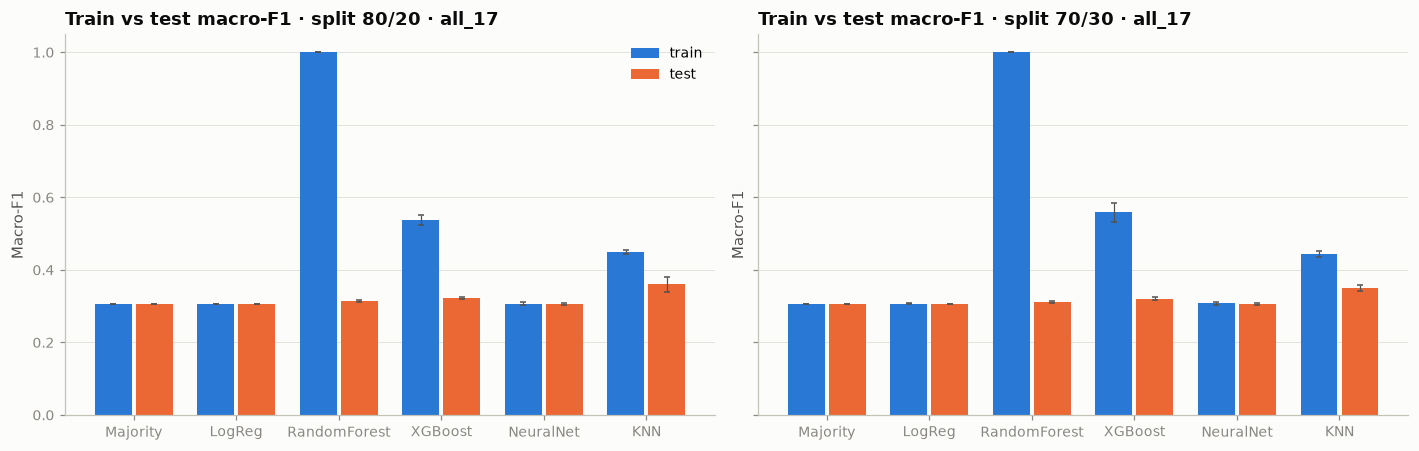

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
long = pd.concat([
    base.assign(part="train", value=base["train_macro_f1"]),
    base.assign(part="test", value=base["test_macro_f1"]),
])
for ax, split in zip(axes, base["split"].unique()):
    grouped_bars(ax, long[long["split"] == split], "model", "part", "value",
                 series_order=["train", "test"], ylabel="Macro-F1",
                 title=f"Train vs test macro-F1 · split {split} · {base_fs}")
axes[0].legend(loc="upper right")
fig.tight_layout()
save_fig(fig, "06_train_vs_test_macro_f1")
plt.show()

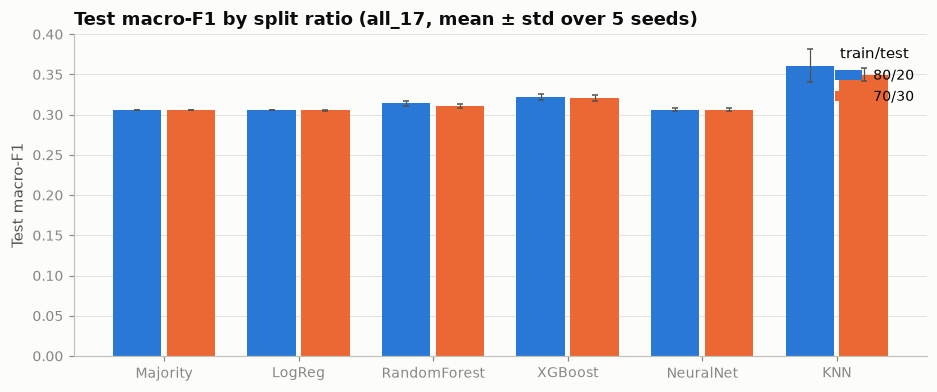

In [16]:
fig, ax = plt.subplots(figsize=(10, 3.8))
grouped_bars(ax, base, "model", "split", "test_macro_f1", ylabel="Test macro-F1",
             title=f"Test macro-F1 by split ratio ({base_fs}, mean ± std over {N_REPEATS} seeds)")
ax.legend(title="train/test", loc="upper right")
save_fig(fig, "07_split_ratio_comparison")
plt.show()

### 6.2 Minority classes: can any model find Serious and Fatal accidents?

In [17]:
mean_std_table(base, ["split", "model"], MINORITY_METRICS)

test_serious_recall test_serious_precision test_fatal_recall test_fatal_precision
split model                                                                                         
80/20 Majority           0.000 ± 0.000          0.000 ± 0.000     0.000 ± 0.000        0.000 ± 0.000
      LogReg             0.000 ± 0.000          0.000 ± 0.000     0.000 ± 0.000        0.000 ± 0.000
      RandomForest       0.013 ± 0.004          0.805 ± 0.051     0.000 ± 0.000        0.000 ± 0.000
      XGBoost            0.027 ± 0.005          0.422 ± 0.080     0.000 ± 0.000        0.000 ± 0.000
      NeuralNet          0.001 ± 0.003          0.100 ± 0.224     0.000 ± 0.000        0.000 ± 0.000
      KNN                0.063 ± 0.011          0.283 ± 0.037     0.039 ± 0.027        0.467 ± 0.361
70/30 Majority           0.000 ± 0.000          0.000 ± 0.000     0.000 ± 0.000        0.000 ± 0.000
      LogReg             0.000 ± 0.001          0.100 ± 0.224     0.000 ± 0.000        0.000 ± 0.000
      RandomForest       0.008 ± 0.004          0.878 ± 0.125     0.000 ± 0.000        0.000 ± 0.000
      XGBoost            0.025 ± 0.005          0.430 ± 0.138     0.000 ± 0.000        0.000 ± 0.000
      NeuralNet          0.001 ± 0.003          0.075 ± 0.168     0.000 ± 0.000        0.000 ± 0.000
      KNN                0.070 ± 0.008          0.328 ± 0.042     0.013 ± 0.012        0.440 ± 0.518

### 6.3 Feature-set comparison
The same models and seeds on different X columns. Because the seeds are shared, differences come from the **features**, not from different splits.

In [18]:
mean_std_table(grid, ["feature_set", "split", "model"],
               ["train_accuracy", "test_accuracy", "train_macro_f1", "test_macro_f1",
                "test_balanced_accuracy", "test_fatal_recall"])

train_accuracy  test_accuracy train_macro_f1  test_macro_f1 test_balanced_accuracy test_fatal_recall
feature_set             split model                                                                                                            
all_17                  80/20 Majority      0.846 ± 0.000  0.846 ± 0.000  0.305 ± 0.000  0.305 ± 0.000          0.333 ± 0.000     0.000 ± 0.000
                              LogReg        0.846 ± 0.000  0.846 ± 0.000  0.306 ± 0.001  0.305 ± 0.000          0.333 ± 0.000     0.000 ± 0.000
                              RandomForest  1.000 ± 0.000  0.847 ± 0.001  1.000 ± 0.000  0.314 ± 0.003          0.337 ± 0.001     0.000 ± 0.000
                              XGBoost       0.876 ± 0.001  0.844 ± 0.001  0.537 ± 0.014  0.322 ± 0.003          0.340 ± 0.002     0.000 ± 0.000
                              NeuralNet     0.846 ± 0.001  0.846 ± 0.000  0.307 ± 0.004  0.306 ± 0.002          0.334 ± 0.001     0.000 ± 0.000
                              KNN           0.867 ± 0.001  0.833 ± 0.002  0.449 ± 0.006  0.361 ± 0.020          0.358 ± 0.011     0.039 ± 0.027
                        70/30 Majority      0.846 ± 0.000  0.846 ± 0.000  0.305 ± 0.000  0.305 ± 0.000          0.333 ± 0.000     0.000 ± 0.000
                              LogReg        0.846 ± 0.000  0.846 ± 0.000  0.306 ± 0.001  0.306 ± 0.001          0.333 ± 0.000     0.000 ± 0.000
                              RandomForest  1.000 ± 0.000  0.847 ± 0.001  1.000 ± 0.000  0.311 ± 0.003          0.336 ± 0.001     0.000 ± 0.000
                              XGBoost       0.879 ± 0.002  0.844 ± 0.003  0.559 ± 0.026  0.321 ± 0.004          0.340 ± 0.002     0.000 ± 0.000
                              NeuralNet     0.846 ± 0.001  0.846 ± 0.000  0.308 ± 0.005  0.306 ± 0.002          0.334 ± 0.001     0.000 ± 0.000
                              KNN           0.866 ± 0.001  0.836 ± 0.003  0.443 ± 0.009  0.350 ± 0.008          0.353 ± 0.004     0.013 ± 0.012
without_lanes_alignment 80/20 Majority      0.846 ± 0.000  0.846 ± 0.000  0.305 ± 0.000  0.305 ± 0.000          0.333 ± 0.000     0.000 ± 0.000
                              LogReg        0.846 ± 0.000  0.846 ± 0.000  0.306 ± 0.001  0.305 ± 0.000          0.333 ± 0.000     0.000 ± 0.000
                              RandomForest  1.000 ± 0.000  0.847 ± 0.001  1.000 ± 0.000  0.327 ± 0.009          0.344 ± 0.005     0.019 ± 0.018
                              XGBoost       0.874 ± 0.003  0.845 ± 0.001  0.524 ± 0.006  0.324 ± 0.003          0.341 ± 0.001     0.000 ± 0.000
                              NeuralNet     0.846 ± 0.001  0.846 ± 0.000  0.309 ± 0.007  0.308 ± 0.004          0.334 ± 0.002     0.000 ± 0.000
                              KNN           0.867 ± 0.002  0.836 ± 0.003  0.464 ± 0.009  0.371 ± 0.014          0.365 ± 0.007     0.032 ± 0.023
                        70/30 Majority      0.846 ± 0.000  0.846 ± 0.000  0.305 ± 0.000  0.305 ± 0.000          0.333 ± 0.000     0.000 ± 0.000
                              LogReg        0.846 ± 0.000  0.846 ± 0.000  0.306 ± 0.001  0.306 ± 0.001          0.333 ± 0.000     0.000 ± 0.000
                              RandomForest  1.000 ± 0.000  0.846 ± 0.001  1.000 ± 0.000  0.321 ± 0.006          0.341 ± 0.003     0.013 ± 0.012
                              XGBoost       0.879 ± 0.001  0.844 ± 0.002  0.552 ± 0.022  0.322 ± 0.005          0.340 ± 0.003     0.000 ± 0.000
                              NeuralNet     0.851 ± 0.010  0.844 ± 0.003  0.333 ± 0.048  0.313 ± 0.012          0.336 ± 0.005     0.000 ± 0.000
                              KNN           0.867 ± 0.002  0.837 ± 0.002  0.468 ± 0.013  0.362 ± 0.011          0.360 ± 0.007     0.017 ± 0.010
only_lanes_alignment    80/20 Majority      0.846 ± 0.000  0.846 ± 0.000  0.305 ± 0.000  0.305 ± 0.000          0.333 ± 0.000     0.000 ± 0.000
                              LogReg        0.846 ± 0.000  0.846 ± 0.000  0.305 ± 0.000  0.305 ± 0.000          0.333 ± 0.000     0.000 ± 0.000
           

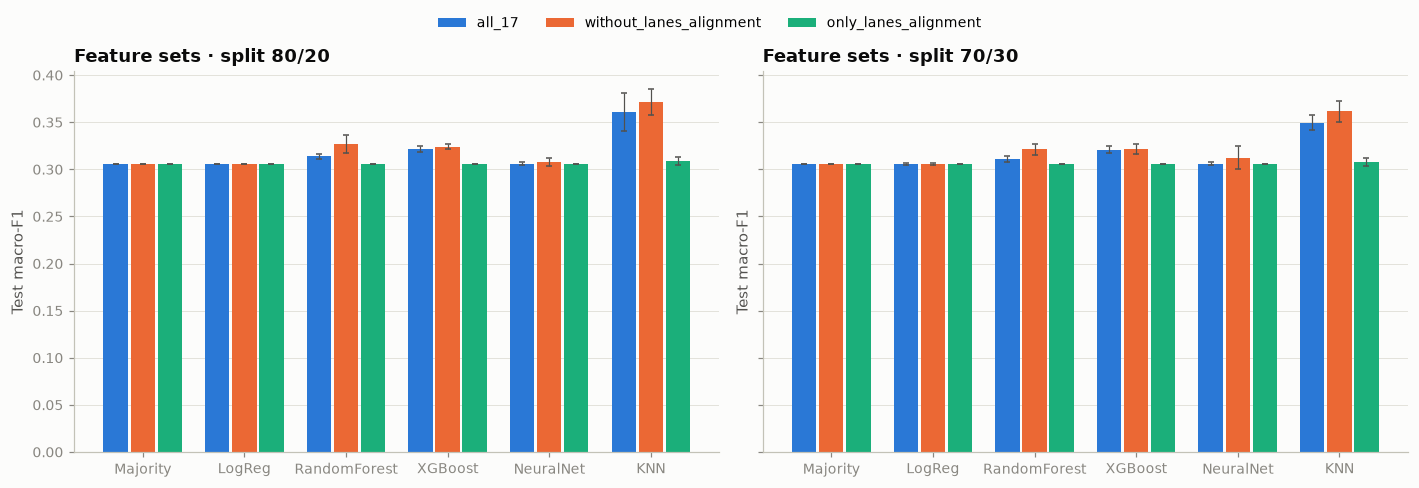

In [19]:
fig, axes = plt.subplots(1, len(TEST_SIZES), figsize=(6.5 * len(TEST_SIZES), 4.2), sharey=True, squeeze=False)
for ax, ts in zip(axes[0], TEST_SIZES):
    grouped_bars(ax, grid[grid["test_size"] == ts], "model", "feature_set", "test_macro_f1",
                 series_order=list(FEATURE_SETS), ylabel="Test macro-F1",
                 title=f"Feature sets · split {split_label(ts)}")
handles, labels = axes[0][0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=len(FEATURE_SETS), bbox_to_anchor=(0.5, 1.06))
fig.tight_layout()
save_fig(fig, "08_feature_set_comparison")
plt.show()

## 7. Drop-one-feature analysis: "what happens without column X?"
For each of the 17 features we retrain **without that one feature**, using the same seeds, and measure the change in test macro-F1:

> **Δ macro-F1 = (score with all features) − (score without the feature)**
> - Δ > 0: removing the feature **hurts**, so the feature is useful
> - Δ ≈ 0: the feature adds nothing *beyond the others*
> - Δ < 0: removing it **helps**, so the feature adds noise

Compare each Δ with its ± std. A Δ smaller than the seed-to-seed noise is not a real effect.

In [20]:
ablation_sets = {"(none dropped)": ALL_FEATURES}
ablation_sets.update({f"drop: {f}": [x for x in ALL_FEATURES if x != f] for f in ALL_FEATURES})

ablation = run_grid(ablation_sets, [ABLATION_TEST_SIZE], N_REPEATS, ABLATION_MODELS)

ref = ablation[ablation["feature_set"] == "(none dropped)"].set_index(["model", "seed"])["test_macro_f1"]
abl = ablation[ablation["feature_set"] != "(none dropped)"].copy()
abl["dropped"] = abl["feature_set"].str.replace("drop: ", "", regex=False)
abl = abl.merge(ref.rename("ref_macro_f1").reset_index(), on=["model", "seed"])
abl["delta_macro_f1"] = abl["ref_macro_f1"] - abl["test_macro_f1"]

delta = (abl.groupby(["dropped", "model"])["delta_macro_f1"].agg(["mean", "std"])
            .unstack("model").swaplevel(axis=1).sort_index(axis=1))
delta = delta.reindex(delta[(ABLATION_MODELS[-1], "mean")].sort_values(ascending=False).index)
print(f"Reference test macro-F1 with all 17 features ({split_label(ABLATION_TEST_SIZE)}):")
print(ref.groupby("model").agg(["mean", "std"]).round(4))
delta.round(4)

  done  (none dropped)                 80/20  × 5 seeds   (    8s)


  done  drop: hour                     80/20  × 5 seeds   (   17s)


  done  drop: time_of_day              80/20  × 5 seeds   (   25s)


  done  drop: is_night                 80/20  × 5 seeds   (   33s)


  done  drop: Day_of_week              80/20  × 5 seeds   (   41s)


  done  drop: is_weekend               80/20  × 5 seeds   (   50s)


... (9 outputs left out)

  done  drop: Driving_experience       80/20  × 5 seeds   (  133s)


  done  drop: Type_of_vehicle          80/20  × 5 seeds   (  141s)


  done  drop: Cause_of_accident        80/20  × 5 seeds   (  150s)
Reference test macro-F1 with all 17 features (80/20):
           mean     std
model                  
LogReg   0.3055  0.0000
XGBoost  0.3220  0.0032


model                    LogReg         XGBoost        
                           mean     std    mean     std
dropped                                                
hour                     0.0000  0.0000  0.0047  0.0049
Types_of_Junction        0.0000  0.0001  0.0040  0.0055
time_of_day             -0.0000  0.0000  0.0028  0.0060
Light_conditions        -0.0000  0.0000  0.0024  0.0031
Day_of_week              0.0000  0.0000  0.0015  0.0052
Weather_conditions      -0.0004  0.0009  0.0012  0.0049
Lanes_or_Medians         0.0000  0.0001  0.0008  0.0049
Road_surface_conditions -0.0004  0.0009  0.0006  0.0027
Road_surface_type        0.0000  0.0001  0.0004  0.0032
Age_band_of_driver       0.0000  0.0001  0.0001  0.0027
is_weekend               0.0000  0.0000  0.0000  0.0057
Area_accident_occurred  -0.0004  0.0009 -0.0004  0.0034
Type_of_vehicle         -0.0000  0.0000 -0.0009  0.0026
Cause_of_accident       -0.0004  0.0009 -0.0017  0.0026
is_night                -0.0004  0.0009 -0.0020  0.0052
Road_alignment          -0.0004  0.0009 -0.0021  0.0054
Driving_experience       0.0000  0.0000 -0.0036  0.0037

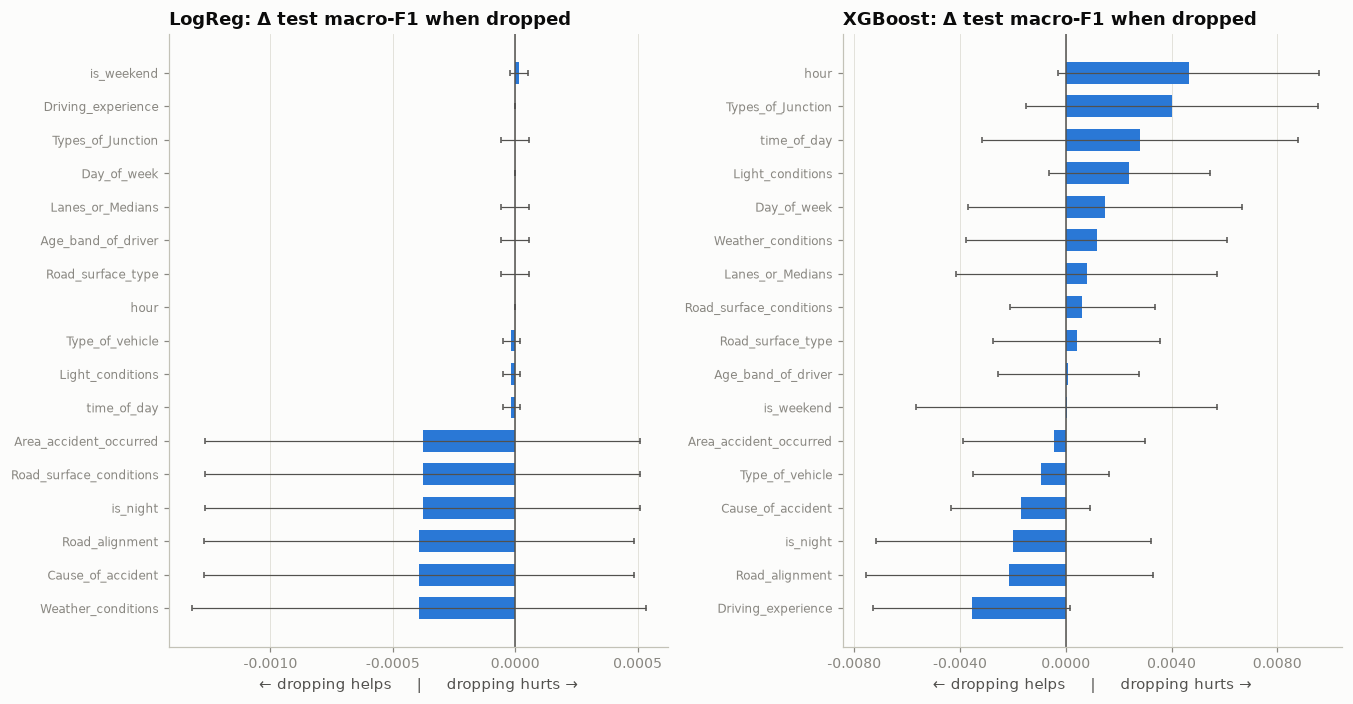

In [21]:
fig, axes = plt.subplots(1, len(ABLATION_MODELS), figsize=(6.2 * len(ABLATION_MODELS), 6.5), squeeze=False)
for ax, m in zip(axes[0], ABLATION_MODELS):
    d = delta[m].sort_values("mean")
    ax.barh(d.index, d["mean"], xerr=d["std"], color=SERIES[0], height=0.65,
            error_kw=dict(ecolor=INK_2, lw=0.8, capsize=2))
    ax.axvline(0, color=INK_2, lw=1)
    ax.set_title(f"{m}: Δ test macro-F1 when dropped", loc="left")
    ax.set_xlabel("← dropping helps     |     dropping hurts →")
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=8)
    ax.xaxis.set_major_locator(plt.MaxNLocator(5))
    ax.xaxis.set_major_formatter(plt.FormatStrFormatter("%.4f"))
fig.tight_layout()
save_fig(fig, "09_drop_one_feature")
plt.show()

## 8. Confusion matrix for one chosen run
Pick any model, feature set and split. The matrix shows **where** the errors go: each row is normalised to 100%, so the diagonal is each class's recall.

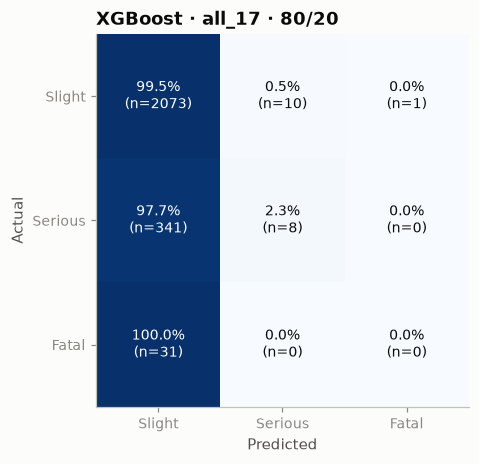

In [22]:
CM_MODEL, CM_FEATURE_SET, CM_TEST_SIZE = "XGBoost", "all_17", TEST_SIZES[0]   # <- change freely

feats = FEATURE_SETS[CM_FEATURE_SET]
X_tr, X_te, y_tr, y_te = train_test_split(data[feats], data[TARGET], test_size=CM_TEST_SIZE,
                                          stratify=data[TARGET], random_state=RANDOM_SEED)
pipe = make_pipeline(feats, CM_MODEL, RANDOM_SEED).fit(X_tr, y_tr)
cm = confusion_matrix(y_te, pipe.predict(X_te), labels=[0, 1, 2])
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100

fig, ax = plt.subplots(figsize=(5.2, 4.4))
ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=100)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{cm_pct[i, j]:.1f}%\n(n={cm[i, j]})", ha="center", va="center", fontsize=9,
                color="white" if cm_pct[i, j] > 55 else INK)
ax.set_xticks(range(3), CLASS_NAMES)
ax.set_yticks(range(3), CLASS_NAMES)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.grid(False)
ax.set_title(f"{CM_MODEL} · {CM_FEATURE_SET} · {split_label(CM_TEST_SIZE)}", loc="left")
save_fig(fig, "10_confusion_matrix")
plt.show()

## 9. 🧪 Quick experiment: try your own columns
Set any X columns and split ratio below and run the cell. Results print as a train/test table and are added to the experiment log.

Available columns: `hour`, `time_of_day`, `is_night`, `Day_of_week`, `is_weekend`, `Light_conditions`, `Weather_conditions`, `Road_surface_conditions`, `Road_surface_type`, `Road_alignment`, `Lanes_or_Medians`, `Types_of_Junction`, `Area_accident_occurred`, `Age_band_of_driver`, `Driving_experience`, `Type_of_vehicle`, `Cause_of_accident`

In [23]:
MY_FEATURES  = ["hour", "is_night", "Light_conditions", "Lanes_or_Medians", "Road_alignment"]
MY_TEST_SIZE = 0.25
MY_MODELS    = ["Majority", "LogReg", "RandomForest", "XGBoost"]

mine = run_experiment(MY_FEATURES, MY_TEST_SIZE, RANDOM_SEED, MY_MODELS, feature_set="my_quick_test")
print(f"{len(MY_FEATURES)} features | split {split_label(MY_TEST_SIZE)} | seed {RANDOM_SEED}")
train_test_table(mine)

5 features | split 75/25 | seed 42


accuracy        balanced_accuracy        macro_f1        serious_recall fatal_recall fatal_precision overfit_gap
                train   test             train   test    train   test           test         test            test    macro_f1
model                                                                                                                        
Majority        0.846  0.846             0.333  0.333    0.305  0.305          0.000          0.0             0.0      -0.000
LogReg          0.846  0.846             0.333  0.333    0.305  0.305          0.000          0.0             0.0      -0.000
RandomForest    0.856  0.836             0.390  0.336    0.412  0.317          0.023          0.0             0.0       0.095
XGBoost         0.851  0.844             0.355  0.338    0.350  0.318          0.021          0.0             0.0       0.032

## 10. Findings

*Numbers below are from the default configuration (80/20 and 70/30, 5 seeds each, seed base 42). If you change the configuration, re-read the tables above.*

### 1. Without imbalance handling, every model collapses towards "always Slight"
| Model (80/20, all 17) | Test accuracy | Test macro-F1 | Test fatal recall | Verdict |
|---|---|---|---|---|
| Majority | 0.846 | 0.305 | 0.000 | reference |
| LogReg | 0.846 | 0.305 | 0.000 | identical to majority, learned nothing usable |
| NeuralNet | 0.846 | 0.306 | 0.000 | identical to majority |
| RandomForest | 0.847 | 0.314 | 0.000 | barely above majority |
| XGBoost | 0.844 | 0.322 | 0.000 | barely above majority |
| KNN | 0.833 | **0.361** | 0.039 | best macro-F1, but still finds almost no fatal cases |

- Test accuracy is about 0.85 for every model, which is **exactly the majority-class rate**. Accuracy cannot tell these models apart.
- **No model reliably detects Fatal accidents** (recall 0–4%). The XGBoost confusion matrix shows all 31 fatal test cases predicted as *Slight*.
- This confirms Research Challenge 1 and the POC conclusion: imbalance correction is **required**, not optional.
- *Note on the POC table:* the POC's LogReg (accuracy 0.404, fatal recall 0.45) and XGBoost (accuracy 0.616) scored far **below** the majority rate. That only happens when a model is pushed towards minority classes, which suggests the POC used some form of class weighting for those two models. Here no model uses weighting, so this notebook is the true **unweighted** baseline.

### 2. Train vs test: Random Forest and XGBoost overfit
- **RandomForest**: train macro-F1 **1.000**, test 0.314 (gap 0.69). It memorises the training data.
- **XGBoost**: train 0.54, test 0.32 (gap about 0.22).
- **KNN**: gap about 0.09. **LogReg / NeuralNet / Majority**: gap about 0, because they predict the same thing on both splits.
- Fully grown trees memorise the 127 training fatal cases but cannot generalise from so few examples. Limiting tree depth or leaf size will be tested alongside imbalance handling.

### 3. Split ratio: 80/20 vs 70/30 makes no meaningful difference
- Test macro-F1 changes by at most about 0.01 between ratios, within the seed-to-seed spread.
- 80/20 keeps more training data (127 vs 111 fatal cases), while 70/30 gives a larger, more stable test set (47 vs 31 fatal cases). **Recommendation:** 80/20 for training final models, and always report mean ± std over several seeds, because with about 31 fatal test cases a single split is unreliable.

### 4. Feature sets
- **`only_lanes_alignment`** (2 features): every model equals the majority baseline. These two columns carry **no predictive signal on their own**, matching their near-zero Cramér's V in notebook 01.
- **`without_lanes_alignment`** (15 features) scores the same as or slightly **better** than all 17. The clearest case is RandomForest (0.327 vs 0.314 at 80/20). Removing them did not hurt any model.
- **Drop-one analysis:** every Δ is smaller than its ± std, so no single feature has a measurable effect *at this stage*. For LogReg every Δ is about 0, because it predicts only *Slight* whatever the features. For XGBoost, `hour`, `Types_of_Junction`, `time_of_day` and `Light_conditions` lean towards useful, consistent with notebook 01, but the effects are within noise.
- **Conclusion:** feature-selection decisions should **not** be made from these unweighted baselines. While models ignore the minority classes, removing a feature barely changes their predictions. The same comparisons will be re-run after imbalance handling, where they become meaningful.

### Next: `04_imbalance_handling.ipynb`
Reuse this exact framework (same configuration cell, same seeds, same metrics) and add, **on the training split only**:
1. `class_weight="balanced"` (LogReg, RandomForest) and sample weights (XGBoost)
2. SMOTENC oversampling (handles categorical features) via an `imblearn` pipeline
3. Re-run the feature-set and drop-one comparisons to decide the final feature set